In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ntpath
from tqdm import tqdm
from sklearn.neighbors import BallTree
from sklearn.neighbors import KDTree
import time

# Wczytanie danych

data = np.loadtxt("wraki-utm.txt")
print(data)

[[ 4.5261542e+05  5.9678155e+06 -6.7200000e+00]
 [ 4.5261523e+05  5.9678155e+06 -6.6700000e+00]
 [ 4.5261505e+05  5.9678156e+06 -6.6100000e+00]
 ...
 [ 4.5262134e+05  5.9677504e+06 -5.3600000e+00]
 [ 4.5262126e+05  5.9677504e+06 -5.2900000e+00]
 [ 4.5262107e+05  5.9677503e+06 -5.3100000e+00]]


In [2]:
# Pobranie danych od uzytkownika
grid = float(input(f'Określ rozdzielczość grid: '))
print(grid)
radius_window = float(input(f'Określ rozmiar okienka (promień okręgu): '))
print(radius_window)
min_points = float(input(f'Określ minimalną liczbe punktów niezbędnych do wyliczenia nowego punktu: '))
print(min_points)

Określ rozdzielczość grid: 0.05
0.05
Określ rozmiar okienka (promień okręgu): 0.5
0.5
Określ minimalną liczbe punktów niezbędnych do wyliczenia nowego punktu: 4
4.0


In [3]:
# Stworzenie siatki, po której się iterujemy
def create_grid(data, resolution):
    min_values = data.min(axis=0)
    max_values = data.max(axis=0)
    x = np.arange(min_values[0], max_values[0], resolution)
    y = np.arange(min_values[1], max_values[1], resolution)
    return np.meshgrid(x, y)

In [4]:
xMeshGrid, yMeshGrid = create_grid(data, grid)
print(f'{xMeshGrid}\n')
print(f'{yMeshGrid}\n')

[[452606.36       452606.41       452606.46       ... 452631.45999999
  452631.50999999 452631.55999999]
 [452606.36       452606.41       452606.46       ... 452631.45999999
  452631.50999999 452631.55999999]
 [452606.36       452606.41       452606.46       ... 452631.45999999
  452631.50999999 452631.55999999]
 ...
 [452606.36       452606.41       452606.46       ... 452631.45999999
  452631.50999999 452631.55999999]
 [452606.36       452606.41       452606.46       ... 452631.45999999
  452631.50999999 452631.55999999]
 [452606.36       452606.41       452606.46       ... 452631.45999999
  452631.50999999 452631.55999999]]

[[5967748.7        5967748.7        5967748.7        ... 5967748.7
  5967748.7        5967748.7       ]
 [5967748.75       5967748.75       5967748.75       ... 5967748.75
  5967748.75       5967748.75      ]
 [5967748.8        5967748.8        5967748.8        ... 5967748.8
  5967748.8        5967748.8       ]
 ...
 [5967819.29999974 5967819.29999974 5967819.2

In [14]:
# Interpolacja metodą Moving Average z BallTree
def moving_average(data, xMesh, yMesh, min_points, radius_window):
    ballTree = BallTree(data[:, :2])
    zMesh = np.empty((xMeshGrid.shape[0], xMeshGrid.shape[1]))

    for i in tqdm(range(xMesh.shape[0]), desc='Loading...'):
        for j in range(xMesh.shape[1]):
            # obliczanie wartości po okręgu
            idx = ballTree.query_radius([[xMesh[i, j], yMesh[i, j]]], r=radius_window)

            if len(idx[0]) < min_points:
                zMesh[i, j] = np.NaN
            else:
                zMesh[i, j] = np.mean(data[idx[0], 2])
    return zMesh

In [5]:
# Interpolacja metodą Moving Average z KDTree
def moving_average_kdtree(data, xMesh, yMesh, min_points, radius_window):
    ballTree = KDTree(data[:, :2])
    zMesh = np.empty((xMeshGrid.shape[0], xMeshGrid.shape[1]))

    for i in tqdm(range(xMesh.shape[0]), desc='Loading...'):
        for j in range(xMesh.shape[1]):
            idx = ballTree.query_radius([[xMesh[i, j], yMesh[i, j]]], r=radius_window)

            if len(idx[0]) < min_points:
                zMesh[i, j] = np.NaN
            else:
                zMesh[i, j] = np.mean(data[idx[0], 2])
    return zMesh

In [16]:
start = time.time()
zMeshGrid = moving_average(data, xMeshGrid, yMeshGrid, min_points, radius_window)
print(f'{zMeshGrid}\n')
end = time.time()
print(end - start)

Loading...: 100%|██████████| 708/708 [00:24<00:00, 28.54it/s]

[[nan nan nan ... nan nan nan]
 [nan nan nan ... nan nan nan]
 [nan nan nan ... nan nan nan]
 ...
 [nan nan nan ... nan nan nan]
 [nan nan nan ... nan nan nan]
 [nan nan nan ... nan nan nan]]

24.93702244758606


In [6]:
start = time.time()
zMeshGrid = moving_average_kdtree(data, xMeshGrid, yMeshGrid, min_points, radius_window)
print(f'{zMeshGrid}\n')
end = time.time()
print(end - start)

Loading...: 100%|██████████| 1415/1415 [01:35<00:00, 14.82it/s]

[[nan nan nan ... nan nan nan]
 [nan nan nan ... nan nan nan]
 [nan nan nan ... nan nan nan]
 ...
 [nan nan nan ... nan nan nan]
 [nan nan nan ... nan nan nan]
 [nan nan nan ... nan nan nan]]

95.63897323608398


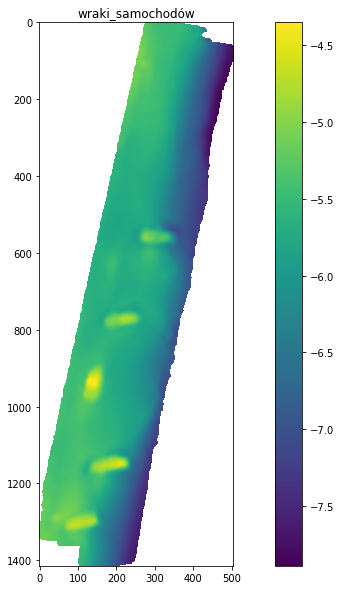

In [7]:
# Wyświetlenie wyniku
import matplotlib.pyplot as plt
plt.rcParams['figure.figsize'] = [15, 10]

plt.figure()
plt.title("wraki_samochodów")
p = plt.imshow(zMeshGrid)
plt.colorbar(p)
plt.show()

In [8]:
# Zapis do pliku CSV
data = {'X': xMeshGrid.flatten(), 'Y': yMeshGrid.flatten(), 'Z': zMeshGrid.flatten()}
df = pd.DataFrame(data)
df.to_csv("wraki_samochodów_outout_5.csv", header=False, sep=' ', na_rep='NaN')